# 18 — Capstone: build and evaluate a document scanner

**Level:** Advanced project · 90–150 minutes  
**Prerequisites:** 06 thresholding; 08 contours; 09 perspective transforms

## What you will build and learn

- Find a page from image evidence rather than supplied corners.
- Order a convex quadrilateral and reject missing or ambiguous detections.
- Rectify perspective and create a readable binary document.
- Evaluate geometry and save a reusable scanning pipeline.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## The task and its assumptions

We will photograph a generated document, detect its outline, straighten it, and improve
its text contrast. **This is image processing, not optical character recognition (OCR):**
the scanner never turns pixels into recognized words or searchable text.

Our detector assumes one mostly bright, flat page on a darker background, with all four
corners visible. We know the generated page's true corners for evaluation, but detection
never receives them. Separate what the algorithm knows from what the evaluator knows.

## Step 1 — Create a document and simulate a photograph

The original image is the clean reference. Drawing text ourselves gives an offline,
repeatable example without external photos or fonts. A camera image will have different
geometry, uneven illumination, and noise.


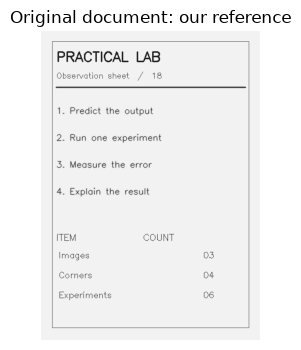

In [2]:
page_width, page_height = 440, 620
document = np.full((page_height, page_width, 3), 242, np.uint8)
cv2.putText(document, 'PRACTICAL LAB', (30, 60), cv2.FONT_HERSHEY_SIMPLEX, .9, (30, 30, 30), 2)
cv2.putText(document, 'Observation sheet  /  18', (30, 94), cv2.FONT_HERSHEY_SIMPLEX, .52, (70, 70, 70), 1)
cv2.line(document, (30, 112), (410, 112), (65, 65, 65), 2)
for index, text in enumerate(['1. Predict the output', '2. Run one experiment',
                              '3. Measure the error', '4. Explain the result']):
    cv2.putText(document, text, (30, 165 + 54 * index), cv2.FONT_HERSHEY_SIMPLEX,
                .58, (45, 45, 45), 1, cv2.LINE_AA)
cv2.putText(document, 'ITEM              COUNT', (30, 420), cv2.FONT_HERSHEY_SIMPLEX, .6, (45, 45, 45), 1)
for index, (item, count) in enumerate([('Images', '03'), ('Corners', '04'), ('Experiments', '06')]):
    y = 455 + 40 * index
    cv2.putText(document, item, (35, y), cv2.FONT_HERSHEY_SIMPLEX, .56, (50, 50, 50), 1)
    cv2.putText(document, count, (325, y), cv2.FONT_HERSHEY_SIMPLEX, .56, (50, 50, 50), 1)
cv2.rectangle(document, (22, 20), (417, 595), (90, 90, 90), 1)
show_images([document], ['Original document: our reference'])


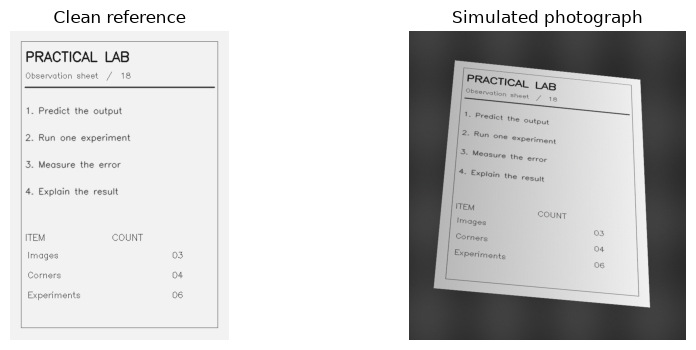

In [3]:
reference_corners = np.float32([[0, 0], [page_width - 1, 0],
                                 [page_width - 1, page_height - 1], [0, page_height - 1]])
true_photo_corners = np.float32([[120, 75], [600, 125], [625, 715], [65, 665]])
true_H = cv2.getPerspectiveTransform(reference_corners, true_photo_corners)
photo_size = (720, 800)  # width, height

# Illumination changes pixels before the known geometric warp.
illumination = np.linspace(.76, 1.0, page_width, dtype=np.float32)[None, :, None]
lit_document = np.clip(document.astype(np.float32) * illumination, 0, 255).astype(np.uint8)
warped_page = cv2.warpPerspective(lit_document, true_H, photo_size)
page_footprint = cv2.warpPerspective(np.full(document.shape[:2], 255, np.uint8), true_H,
                                   photo_size, flags=cv2.INTER_NEAREST)
yy, xx = np.indices((photo_size[1], photo_size[0]))
background_gray = (55 + 6 * np.sin(xx / 31) + 5 * np.cos(yy / 39)).astype(np.uint8)
photograph = cv2.cvtColor(background_gray, cv2.COLOR_GRAY2BGR)
photograph[page_footprint > 0] = warped_page[page_footprint > 0]
photograph = np.clip(photograph.astype(np.float32) + rng.normal(0, 1.8, photograph.shape), 0, 255).astype(np.uint8)
show_images([document, photograph], ['Clean reference', 'Simulated photograph'], cols=2)
assert photograph.shape == (800, 720, 3)


## Step 2 — Inspect the evidence for a page boundary

Blur reduces sensor noise. Canny shows strong intensity changes, including both page
edges and text. A bright-region threshold offers a simpler route in our controlled
scene. Otsu selects the global threshold from the histogram. Closing bridges small
dark gaps; it cannot reliably recover a page on a similarly bright tabletop.

We will find contours in the bright mask. The detector checks area, convexity, corner
count, and whether the outline touches the frame. These tests reject some bad inputs;
they are not a semantic proof that a region is paper.


Otsu threshold: 133.0


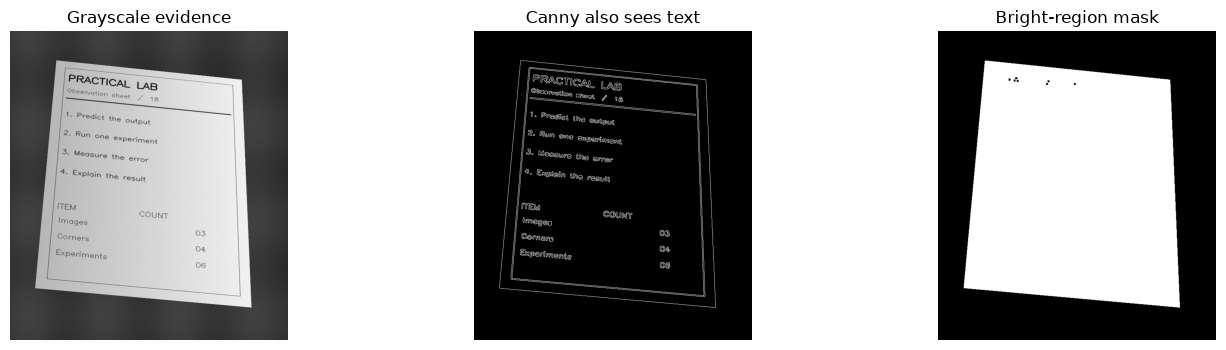

In [4]:
photo_gray = cv2.cvtColor(photograph, cv2.COLOR_BGR2GRAY)
photo_blur = cv2.GaussianBlur(photo_gray, (5, 5), 0)
photo_edges = cv2.Canny(photo_blur, 60, 150)
otsu_value, bright_mask = cv2.threshold(photo_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bright_mask = cv2.morphologyEx(bright_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
print('Otsu threshold:', otsu_value)
show_images([photo_gray, photo_edges, bright_mask], ['Grayscale evidence', 'Canny also sees text', 'Bright-region mask'])


Area: 307200 | simplified vertices: 4


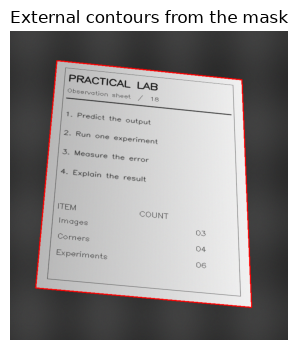

In [5]:
page_contours, _ = cv2.findContours(bright_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour_view = photograph.copy()
cv2.drawContours(contour_view, page_contours, -1, (0, 0, 255), 2)
for contour in sorted(page_contours, key=cv2.contourArea, reverse=True)[:5]:
    perimeter = cv2.arcLength(contour, True)
    approximation = cv2.approxPolyDP(contour, .02 * perimeter, True)
    print('Area:', round(cv2.contourArea(contour)), '| simplified vertices:', len(approximation))
show_images([contour_view], ['External contours from the mask'])


## Step 3 — Order corners and reject ambiguous candidates

`approxPolyDP` reduces a contour to a polygon, with epsilon proportional to perimeter.
Four vertices alone are insufficient: require a convex quadrilateral with distinct
corners and adequate area. To order its vertices, sort around the centroid, orient the
cycle consistently, then start at the unique top-left candidate.

The top-left convention here uses the smallest `x+y`. A nearly diamond-shaped page can
make that choice ambiguous, so we reject near ties and ask for a less rotated photo.
This geometric convention does **not** recognize which way the text should face; an
upside-down document still needs a separate orientation decision.


In [6]:
class PageDetectionError(ValueError):
    pass

def order_page_corners(points, tie_tolerance=2.0):
    points = np.asarray(points, dtype=np.float32).reshape(-1, 2)
    if points.shape != (4, 2) or not np.isfinite(points).all():
        raise PageDetectionError('Need exactly four finite corner coordinates.')
    separation = np.linalg.norm(points[:, None] - points[None, :], axis=2)
    np.fill_diagonal(separation, np.inf)
    if separation.min() < 5:
        raise PageDetectionError('Corners are duplicate or too close together.')
    center = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
    cyclic = points[np.argsort(angles)]
    if not cv2.isContourConvex(cyclic.reshape(-1, 1, 2)) or cv2.contourArea(cyclic) < 25:
        raise PageDetectionError('The corners must form a non-degenerate convex quadrilateral.')
    signed_area2 = np.sum(cyclic[:, 0] * np.roll(cyclic[:, 1], -1)
                         - cyclic[:, 1] * np.roll(cyclic[:, 0], -1))
    if signed_area2 < 0:
        cyclic = cyclic[::-1]
    corner_sums = cyclic.sum(axis=1)
    ranked_sums = np.sort(corner_sums)
    if ranked_sums[1] - ranked_sums[0] <= tie_tolerance:
        raise PageDetectionError('Top-left corner is ambiguous; reduce page rotation.')
    ordered = np.roll(cyclic, -int(np.argmin(corner_sums)), axis=0)
    return ordered.astype(np.float32)  # top-left, top-right, bottom-right, bottom-left

# Changing input order must not change the ordered output.
ordered_truth = order_page_corners(true_photo_corners[[2, 0, 3, 1]])
assert np.array_equal(ordered_truth, true_photo_corners)


In [7]:
def detect_page(image, epsilon_fraction=.02, min_area_fraction=.15):
    if image is None or image.ndim != 3 or image.shape[2] != 3 or image.size == 0:
        raise PageDetectionError('Provide a non-empty BGR image.')
    if image.dtype != np.uint8:
        raise PageDetectionError('This detector expects a uint8 image.')
    if not 0 < epsilon_fraction < .15 or not 0 < min_area_fraction < .95:
        raise ValueError('Use epsilon in (0,.15), area fraction in (0,.95).')
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    smooth = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    height, width = mask.shape
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if not min_area_fraction * mask.size <= area <= .95 * mask.size:
            continue
        approx = cv2.approxPolyDP(contour, epsilon_fraction * cv2.arcLength(contour, True), True)
        if len(approx) != 4 or not cv2.isContourConvex(approx):
            continue
        points = approx.reshape(4, 2)
        if (points[:, 0].min() < 3 or points[:, 1].min() < 3
                or points[:, 0].max() >= width - 3 or points[:, 1].max() >= height - 3):
            continue  # Cannot trust a page cut off by the frame.
        try:
            ordered = order_page_corners(points)
        except PageDetectionError:
            continue
        candidates.append((area, ordered))
    candidates.sort(key=lambda pair: pair[0], reverse=True)
    if not candidates:
        raise PageDetectionError('No plausible page. Check contrast, visible corners, and area limits.')
    if len(candidates) > 1 and candidates[1][0] >= .75 * candidates[0][0]:
        raise PageDetectionError('Multiple similarly sized pages: choose or crop one explicitly.')
    return {'corners': candidates[0][1], 'mask': mask, 'area': candidates[0][0],
            'candidate_count': len(candidates)}

detection = detect_page(photograph)
estimated_corners = detection['corners']
print('Estimated corners:', estimated_corners.tolist())
print('Plausible candidates:', detection['candidate_count'])


Estimated corners: [[121.0, 76.0], [600.0, 125.0], [625.0, 715.0], [66.0, 665.0]]
Plausible candidates: 1


Corner errors in photograph pixels: [1.414 0.    0.    1.   ]
Mean corner error: 0.6035534


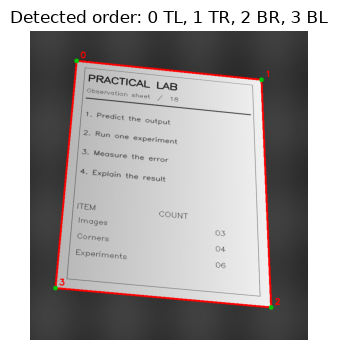

In [8]:
detected_view = photograph.copy()
cv2.polylines(detected_view, [np.rint(estimated_corners).astype(np.int32)], True, (0, 0, 255), 3)
for index, point in enumerate(estimated_corners.astype(int)):
    cv2.circle(detected_view, tuple(point), 6, (0, 200, 0), -1)
    cv2.putText(detected_view, str(index), tuple(point + [10, -8]),
                cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 0, 255), 2)
corner_errors = np.linalg.norm(estimated_corners - true_photo_corners, axis=1)
print('Corner errors in photograph pixels:', np.round(corner_errors, 3))
print('Mean corner error:', corner_errors.mean())
assert corner_errors.mean() < 6, 'Inspect the detector if the generated page is poorly localized.'
show_images([detected_view], ['Detected order: 0 TL, 1 TR, 2 BR, 3 BL'])


## Step 4 — Rectify perspective with the estimated corners

A homography maps a flat quadrilateral to a rectangle. Source and destination corners
must have matching order. `warpPerspective` takes `(output_width, output_height)`.
For this evaluation, the true document dimensions are known, so both images share a
coordinate system. For a personal photo, an edge-length estimate gives a useful output
size, but cannot recover the page's exact physical aspect ratio from arbitrary perspective.
Supply a known page ratio when geometric proportions matter.


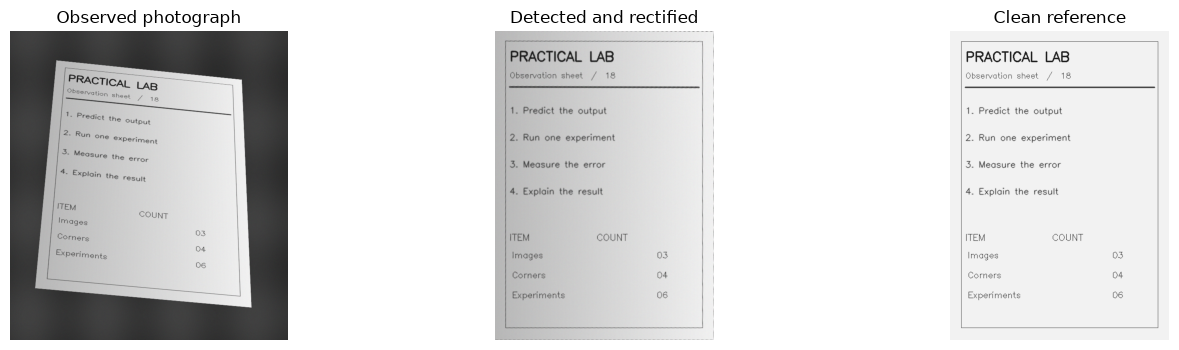

In [9]:
def rectify_page(image, corners, output_size=None):
    ordered = order_page_corners(corners)
    tl, tr, br, bl = ordered
    if output_size is None:
        width = round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
        height = round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))
    else:
        width, height = map(int, output_size)
    if width < 10 or height < 10 or width > 8000 or height > 8000:
        raise ValueError('Choose output dimensions between 10 and 8000 pixels.')
    destination = np.float32([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]])
    H = cv2.getPerspectiveTransform(ordered, destination)
    if not np.isfinite(H).all() or abs(np.linalg.det(H)) < 1e-12:
        raise PageDetectionError('The estimated perspective transform is singular.')
    return cv2.warpPerspective(image, H, (width, height)), H

rectified, estimated_H = rectify_page(photograph, estimated_corners, (page_width, page_height))
show_images([photograph, rectified, document], ['Observed photograph', 'Detected and rectified', 'Clean reference'])
assert rectified.shape == document.shape


Interior point errors in reference pixels: [1.064 0.296 0.026 0.535]
Interior pixel MAE (not purely geometric): 31.707143447705665


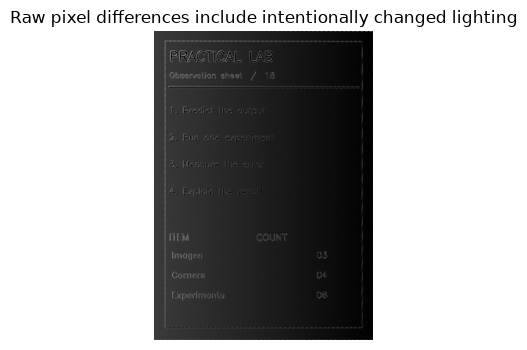

In [10]:
# Evaluate geometry on interior points, not just the four fitted corner points.
reference_checks = np.float32([[[60, 80], [220, 300], [380, 540], [95, 430]]])
photo_checks = cv2.perspectiveTransform(reference_checks, true_H)
recovered_checks = cv2.perspectiveTransform(photo_checks, estimated_H)
interior_errors = np.linalg.norm(recovered_checks - reference_checks, axis=2).ravel()
print('Interior point errors in reference pixels:', np.round(interior_errors, 3))
assert interior_errors.mean() < 6
# Pixel differences include illumination, sensor noise, and two interpolation passes.
pixel_error = cv2.absdiff(document, rectified)
print('Interior pixel MAE (not purely geometric):', pixel_error[15:-15, 15:-15].mean())
show_images([pixel_error], ['Raw pixel differences include intentionally changed lighting'])


## Step 5 — Improve readability and compare threshold parameters

Adaptive thresholding estimates local brightness before selecting ink. For dark ink,
`THRESH_BINARY_INV` produces a mask with white ink pixels, useful for evaluation. Invert
that mask to export a conventional black-on-white document. `blockSize` must be odd and
greater than 1; `C` is subtracted from the local reference. A larger C in inverse mode
selects fewer pixels, potentially losing faint strokes.

The clean reference's pixels below 160 define our ink labels. Anti-aliased text has
partial gray edge pixels, so this cutoff is an explicit labeling convention.


Ink IoU: 0.5180738873781257


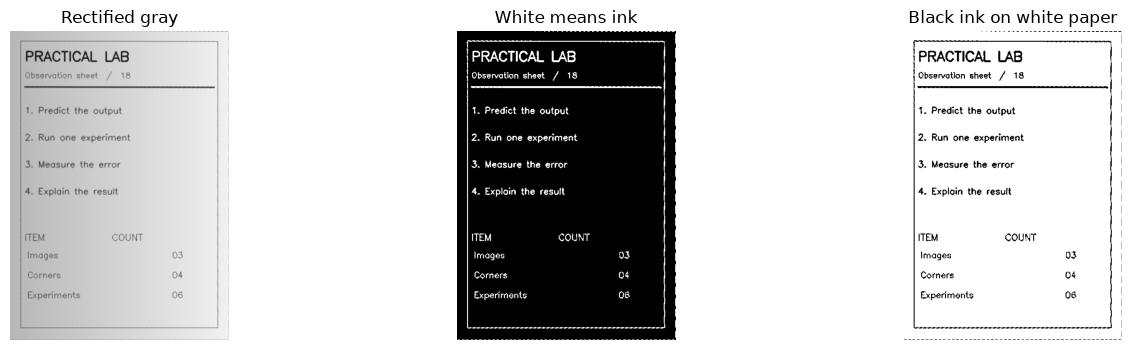

In [11]:
rectified_gray = cv2.cvtColor(rectified, cv2.COLOR_BGR2GRAY)
reference_gray = cv2.cvtColor(document, cv2.COLOR_BGR2GRAY)
ink_truth = reference_gray < 160

def threshold_ink(gray, block_size=31, c_value=10):
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY_INV, block_size, c_value)

def ink_iou(predicted, truth):
    p, t = np.asarray(predicted) > 0, np.asarray(truth) > 0
    union = np.count_nonzero(p | t)
    return np.count_nonzero(p & t) / union if union else 1.0

ink_mask = threshold_ink(rectified_gray)
binary_scan = cv2.bitwise_not(ink_mask)
print('Ink IoU:', ink_iou(ink_mask, ink_truth))
show_images([rectified_gray, ink_mask, binary_scan], ['Rectified gray', 'White means ink', 'Black ink on white paper'])
assert set(np.unique(binary_scan)).issubset({0, 255})


C= 3: IoU=0.464, extra=8987, missed=220
C=10: IoU=0.518, extra=6887, missed=379
C=22: IoU=0.576, extra=4514, missed=867


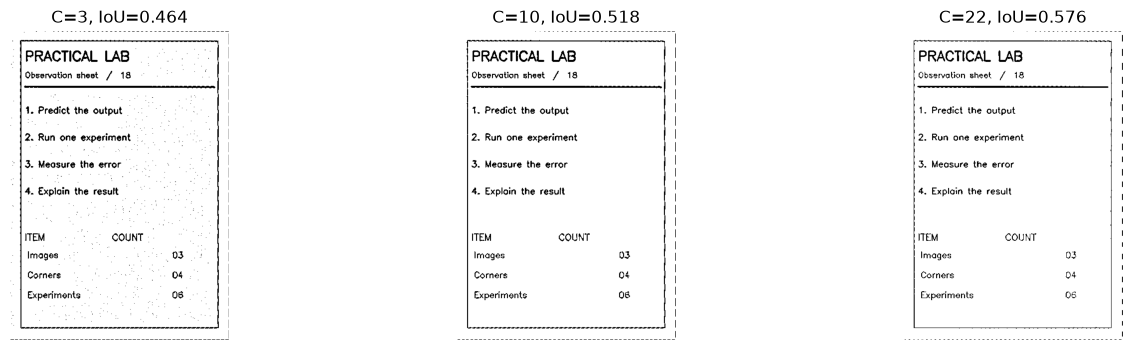

In [12]:
threshold_variants, threshold_titles = [], []
for c_value in [3, 10, 22]:
    candidate = threshold_ink(rectified_gray, block_size=31, c_value=c_value)
    selected = candidate > 0
    extra = np.count_nonzero(selected & ~ink_truth)
    missed = np.count_nonzero(~selected & ink_truth)
    score = ink_iou(candidate, ink_truth)
    print(f'C={c_value:2}: IoU={score:.3f}, extra={extra}, missed={missed}')
    threshold_variants.append(cv2.bitwise_not(candidate))
    threshold_titles.append(f'C={c_value}, IoU={score:.3f}')
show_images(threshold_variants, threshold_titles)
# These comparisons use one synthetic page, not an independent accuracy benchmark.


## Step 6 — Package the mini-project and exercise failure paths

Keep detection, geometry, and thresholding as separate functions: their outputs reveal
which stage failed. The combined function returns both a display image and diagnostics.
Expected detection failures should produce clear messages, not a silently guessed scan.


In [13]:
def scan_document(image, output_size=None):
    found = detect_page(image)
    straight, transform = rectify_page(image, found['corners'], output_size)
    gray = cv2.cvtColor(straight, cv2.COLOR_BGR2GRAY)
    ink = threshold_ink(gray)
    return {'corners': found['corners'], 'rectified': straight,
            'binary': cv2.bitwise_not(ink), 'transform': transform,
            'detection_mask': found['mask']}

scan = scan_document(photograph, (page_width, page_height))
out_dir = ROOT / 'outputs' / '18_scanner'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'photograph.png', photograph)
save_image(out_dir / 'detected_page.png', detected_view)
save_image(out_dir / 'rectified_color.png', scan['rectified'])
save_image(out_dir / 'binary_scan.png', scan['binary'])
import json
report = {'estimated_corners': scan['corners'].tolist(),
          'mean_corner_error_pixels': float(corner_errors.mean()),
          'ink_IoU': float(ink_iou(ink_mask, ink_truth)),
          'scope': 'One generated flat bright page; no OCR or real-world accuracy claim'}
(out_dir / 'scan_report.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
print('Saved scan images and diagnostics to', out_dir)


Saved scan images and diagnostics to C:\Users\Hareram ray\AI\OpencvPractical\outputs\18_scanner


Missing page: No plausible page. Check contrast, visible corners, and area limits.
Two similar pages: Multiple similarly sized pages: choose or crop one explicitly.


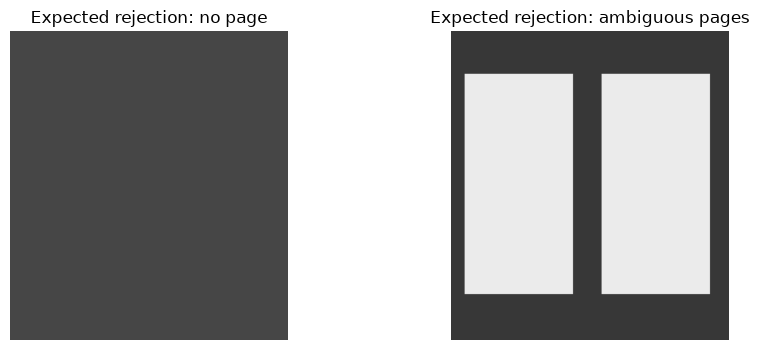

In [14]:
blank_photo = np.full_like(photograph, 70)
two_pages = np.full_like(photograph, 55)
cv2.rectangle(two_pages, (35, 110), (315, 680), (235, 235, 235), -1)
cv2.rectangle(two_pages, (390, 110), (670, 680), (235, 235, 235), -1)
for label, difficult_image in [('Missing page', blank_photo), ('Two similar pages', two_pages)]:
    try:
        detect_page(difficult_image)
    except PageDetectionError as error:
        print(label + ':', error)
    else:
        raise AssertionError(label + ' should be rejected, not silently selected.')
show_images([blank_photo, two_pages], ['Expected rejection: no page', 'Expected rejection: ambiguous pages'], cols=2)


### Optional: scan your own local photograph

Keep `personal_path=None` for the default lesson. To try your own image, use a path in
`data/personal/`. Photograph one bright flat page on a dark surface and include margins
around every corner. A successful contour detection still needs visual checking. The
algorithm can mistake a bright sign or rectangular object for paper.


In [15]:
personal_path = None  # Example: ROOT / 'data' / 'personal' / 'document.jpg'
if personal_path is None:
    print('Optional personal photo skipped; all core steps used generated data.')
else:
    try:
        personal_image = load_image(personal_path)
        personal_scan = scan_document(personal_image)
        show_images([personal_image, personal_scan['rectified'], personal_scan['binary']],
                    ['Personal photograph', 'Check the estimated geometry', 'Binary result'])
        save_image(out_dir / 'personal_binary_scan.png', personal_scan['binary'])
    except (OSError, ValueError, cv2.error) as error:
        print('Personal scan could not complete:', error)


Optional personal photo skipped; all core steps used generated data.


### Exercises — attempt before the solutions

1. Vary polygon epsilon fractions .005, .02, and .08. Compare corner errors, and catch
   detection failures explicitly. Why can a larger approximation tolerance lose corners?
2. Prove that shuffled input corners produce the same order. Construct a symmetric
   diamond and confirm that our top-left ambiguity guard rejects it.
3. Create an error overlay: green for correct ink, red for extra pixels, blue for missed
   ink. Inspect whether errors cluster along text edges or along one side of the page.

Write your own attempt in a new cell before continuing. A realistic extension is to
collect 10 different pages and lighting conditions, choose settings on some images,
then evaluate once on a separate group.


In [16]:
# Your practice area. Keep the reference variables unchanged.
# Try: candidate = detect_page(photograph, epsilon_fraction=...)


## Worked solutions and interpretation

A stable result across these settings is useful evidence for this page, but not proof
that epsilon is irrelevant. Curved paper, a busy background, or an occluded corner
changes the contour itself. Ordering also cannot fix an incorrectly detected corner.


In [17]:
for epsilon in [.005, .02, .08]:
    try:
        candidate = detect_page(photograph, epsilon_fraction=epsilon)
        errors = np.linalg.norm(candidate['corners'] - true_photo_corners, axis=1)
        print(f'epsilon={epsilon:.3f}: mean corner error={errors.mean():.3f}px')
    except PageDetectionError as error:
        print(f'epsilon={epsilon:.3f}: rejected: {error}')

for permutation in [[3, 2, 1, 0], [1, 3, 0, 2]]:
    assert np.array_equal(order_page_corners(estimated_corners[permutation]), estimated_corners)
diamond = np.float32([[150, 30], [270, 150], [150, 270], [30, 150]])
try:
    order_page_corners(diamond)
except PageDetectionError as error:
    print('Expected diamond rejection:', error)
else:
    raise AssertionError('The top-left ambiguity guard should reject the diamond.')


epsilon=0.005: mean corner error=0.604px
epsilon=0.020: mean corner error=0.604px
epsilon=0.080: mean corner error=0.604px
Expected diamond rejection: Top-left corner is ambiguous; reduce page rotation.


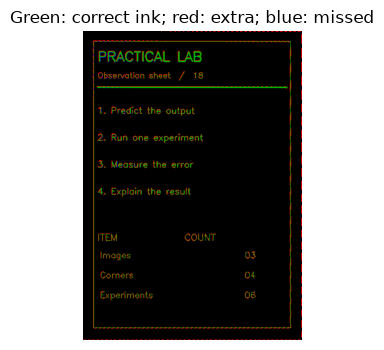

WindowsPath('C:/Users/Hareram ray/AI/OpencvPractical/outputs/18_scanner/ink_error_overlay.png')

In [18]:
selected_ink = ink_mask > 0
error_overlay = np.zeros((*ink_truth.shape, 3), np.uint8)
error_overlay[selected_ink & ink_truth] = (0, 180, 0)
error_overlay[selected_ink & ~ink_truth] = (0, 0, 255)
error_overlay[~selected_ink & ink_truth] = (255, 0, 0)
show_images([error_overlay], ['Green: correct ink; red: extra; blue: missed'])
save_image(out_dir / 'ink_error_overlay.png', error_overlay)


### Real-world pitfalls and completion checklist

- Shadows and white tabletops can merge the page with its background. Inspect the mask.
- Cropped corners and multiple pages need user input or a different detector.
- A single homography assumes flat paper; it cannot unbend a curved book page or undo
  lens distortion. Camera calibration and dedicated dewarping address different issues.
- Blur, tiny text, and compression can destroy detail that thresholding cannot restore.
- A prettier black-and-white result does not establish readable or correctly recognized
  text. This notebook does not perform OCR, language detection, or searchable-PDF creation.
- Four matching corner pairs always fit a homography: verify independent interior points,
  page proportions, and real examples before trusting the result.

You should now be able to explain **image → mask → contour → ordered corners → perspective
warp → ink mask → evaluation → export**, and identify which stage needs attention when a
scan fails. Rebuild the pipeline in your own notebook, then test it on new photographs.

Official references: [Contour approximation](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html),
[Perspective transforms](https://docs.opencv.org/4.x/da/d6e/tutorial_py_geometric_transformations.html),
[Adaptive thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html).
